# **Fine-tuning Vintern-1B-v3_5 on Vietnamese Document KIE Data**

In this notebook, we will fine-tune Vintern-1B on Vietnamese document KIE (Key Information Extraction) data, focusing on header information extraction from administrative documents.

Reference: https://internvl.readthedocs.io/en/latest/internvl2.0/finetune.html

Check it more about us: [Fifth Civil Defender - 5CD - AI](https://huggingface.co/5CD-AI)

Let's start by installing the dependencies and loading the dataset.

In [ ]:
!pip install -q timm einops peft wandb deepspeed accelerate bitsandbytes decord tensorboardX gdown

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 69.2 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.4/59.4 MB 16.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.6/13.6 MB 148.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.2/87.2 kB 10.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.0/54.0 kB 6.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 180.7/180.7 kB 20.3 MB/s eta 0:00:00


In [ ]:
!pip install -U datasets
!pip install -q transformers==4.47.0
# !pip install -q flash_attn==2.7.2.post1

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 511.5/511.5 kB 41.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.7/47.7 MB 50.6 MB/s eta 0:00:00
  Attempting uninstall: pyarrow
    Found existing installation: pyarrow 18.1.0
    Uninstalling pyarrow-18.1.0:
      Successfully uninstalled pyarrow-18.1.0
  Attempting uninstall: datasets
    Found existing installation: datasets 4.0.0
    Uninstalling datasets-4.0.0:
      Successfully uninstalled datasets-4.0.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu12 25.6.0 requires pyarrow<20.0.0a0,>=14.0.0; platform_machine == "x86_64", but you have pyarrow 22.0.0 which is incompatible.
pylibcudf-cu12 25.6.0 requires pyarrow<20.0.0a0,>=14.0.0; platform_machine == "x86_64", but you have pyarrow 22.0.0 which is incompatible.
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.5/43.5 kB 4.7 MB/s eta 0

In [ ]:
!pip install -q flash-attn --no-build-isolation

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.4/8.4 MB 118.3 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done


In [ ]:
!git clone https://github.com/5CD-AI/Vintern.git
%cd Vintern

Cloning into 'Vintern'...
remote: Enumerating objects: 2361, done.
remote: Counting objects: 100% (1/1), done.
remote: Total 2361 (delta 0), reused 0 (delta 0), pack-reused 2360 (from 1)
Receiving objects: 100% (2361/2361), 36.46 MiB | 14.84 MiB/s, done.
Resolving deltas: 100% (1369/1369), done.
/content/Vintern


# **Load exported KIE dataset**

In [ ]:
import json
import os
import zipfile
from PIL import Image
import matplotlib.pyplot as plt
from tqdm import tqdm

# ✅ ĐƯỜNG DẪN TỚI FILE ZIP ĐÃ EXPORT TỪ HỆ THỐNG
EXPORT_ZIP_PATH = "/content/pla_kie.zip"  # Thay đổi path này

# Extract ZIP file
EXTRACT_DIR = "/content/pla_kie"
os.makedirs(EXTRACT_DIR, exist_ok=True)

with zipfile.ZipFile(EXPORT_ZIP_PATH, 'r') as zip_ref:
    zip_ref.extractall(EXTRACT_DIR)

print(f"✅ Extracted dataset to: {EXTRACT_DIR}")
print(f"📁 Contents: {os.listdir(EXTRACT_DIR)}")

✅ Extracted dataset to: /content/pla_kie
📁 Contents: ['images', 'metadata.json', 'val.jsonl', 'train.jsonl']


In [ ]:
# Load training data
train_jsonl_path = os.path.join(EXTRACT_DIR, "train.jsonl")
val_jsonl_path = os.path.join(EXTRACT_DIR, "val.jsonl")
images_dir = os.path.join(EXTRACT_DIR, "images")

# Read training data
train_data = []
with open(train_jsonl_path, 'r', encoding='utf-8') as f:
    for line in f:
        train_data.append(json.loads(line.strip()))

# Read validation data if exists
val_data = []
if os.path.exists(val_jsonl_path):
    with open(val_jsonl_path, 'r', encoding='utf-8') as f:
        for line in f:
            val_data.append(json.loads(line.strip()))

print(f"📊 Training samples: {len(train_data)}")
print(f"📊 Validation samples: {len(val_data)}")
print(f"📁 Images directory: {images_dir}")

# Show sample data structure
print("\n📋 Sample data structure:")
print(json.dumps(train_data[0], ensure_ascii=False, indent=2))

📊 Training samples: 368
📊 Validation samples: 0
📁 Images directory: /content/pla_kie/images

📋 Sample data structure:
{
  "id": "Batch_08_23_03 19_9_2025_dce4b79b-8d40-49cb-b24e-91acd18c08a3",
  "image": "dce4b79b-8d40-49cb-b24e-91acd18c08a3_header.png",
  "conversations": [
    {
      "from": "human",
      "value": "<image>\nBạn là chuyên gia trích xuất thông tin từ tài liệu hành chính Việt Nam. Hãy trích xuất các thông tin sau: Loại văn bản, Số và ký hiệu văn bản, Số viết tay ở góc trên bên phải, Cơ quan chủ quản, Cơ quan ban hành, Ngày tháng năm ban hành, Trích yếu, Người ký.\n\nTrả về JSON theo cấu trúc sau:\n{\n  \"document_type\": \"\",\n  \"document_number_and_symbol\": \"\",\n  \"handwritten_number\": \"\",\n  \"issue_date\": \"\",\n  \"supervising_authority\": \"\",\n  \"issuing_authority\": \"\",\n  \"signer_name\": \"\",\n  \"summary\": \"\"\n}"
    },
    {
      "from": "gpt",
      "value": "{\n  \"document_type\": \"Bảng tổng hợp\",\n  \"document_number_and_symbol\": \

🖼️ Sample images and their KIE extractions:


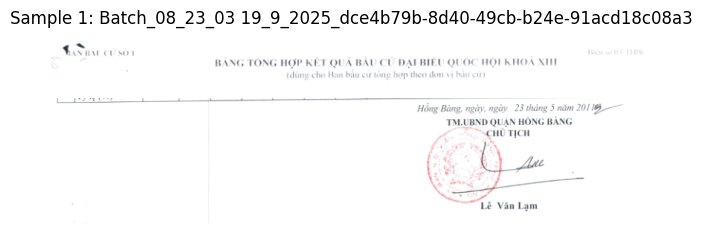

📝 Conversation 1:
👤 human: <image>
Bạn là chuyên gia trích xuất thông tin từ tài liệu hành chính Việt Nam. Hãy trích xuất các thông tin sau: Loại văn bản, Số và ký hiệu văn bản, Số viết tay ở góc trên bên phải, Cơ quan chủ quản, Cơ quan ban hành, Ngày tháng năm ban hành, Trích yếu, Người ký.

Trả về JSON theo cấu trúc sau:
{
  "document_type": "",
  "document_number_and_symbol": "",
  "handwritten_number": "",
  "issue_date": "",
  "supervising_authority": "",
  "issuing_authority": "",
  "signer_name": "",
  "summary": ""
}
👤 gpt: {
  "document_type": "Bảng tổng hợp",
  "document_number_and_symbol": "",
  "handwritten_number": "",
  "issue_date": "23/05/2011",
  "supervising_authority": "",
  "issuing_authority": "Ban bầu cử số 1",
  "signer_name": "Lê Văn Lạm",
  "summary": "BẢNG TỔNG HỢP KẾT QUẢ BẦU CỬ ĐẠI BIỂU QUỐC HỘI KHÓA XIII ( dùng cho Ban bầu cử tổng hợp theo đơn vị bầu cử)"
}


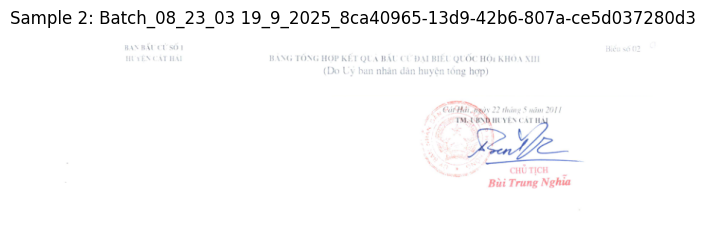

📝 Conversation 2:
👤 human: <image>
Bạn là chuyên gia trích xuất thông tin từ tài liệu hành chính Việt Nam. Hãy trích xuất các thông tin sau: Loại văn bản, Số và ký hiệu văn bản, Số viết tay ở góc trên bên phải, Cơ quan chủ quản, Cơ quan ban hành, Ngày tháng năm ban hành, Trích yếu, Người ký.

Trả về JSON theo cấu trúc sau:
{
  "document_type": "",
  "document_number_and_symbol": "",
  "handwritten_number": "",
  "issue_date": "",
  "supervising_authority": "",
  "issuing_authority": "",
  "signer_name": "",
  "summary": ""
}
👤 gpt: {
  "document_type": "Bảng tổng hợp",
  "document_number_and_symbol": "",
  "handwritten_number": "",
  "issue_date": "22/05/2011",
  "supervising_authority": "Ban bầu cử sô 1",
  "issuing_authority": "HUYỆN CÁT HẢI",
  "signer_name": "Bùi Trung Nghĩa",
  "summary": "BẢNG TỔNG HỢP KẾT QUẢ BẦU CỬ ĐẠI BIỂU QUỐC HỘI KHÓA XIII ( Do Ủy ban nhân dân huyện tổng hợp)"
}


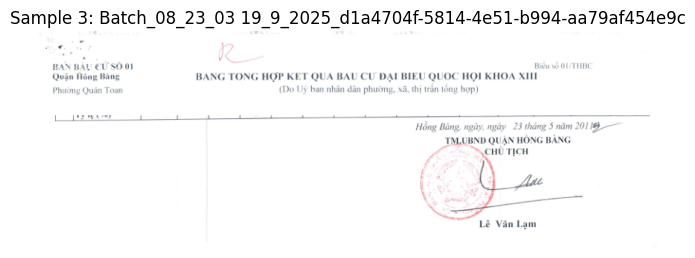

📝 Conversation 3:
👤 human: <image>
Bạn là chuyên gia trích xuất thông tin từ tài liệu hành chính Việt Nam. Hãy trích xuất các thông tin sau: Loại văn bản, Số và ký hiệu văn bản, Số viết tay ở góc trên bên phải, Cơ quan chủ quản, Cơ quan ban hành, Ngày tháng năm ban hành, Trích yếu, Người ký.

Trả về JSON theo cấu trúc sau:
{
  "document_type": "",
  "document_number_and_symbol": "",
  "handwritten_number": "",
  "issue_date": "",
  "supervising_authority": "",
  "issuing_authority": "",
  "signer_name": "",
  "summary": ""
}
👤 gpt: {
  "document_type": "Bảng tổng hợp",
  "document_number_and_symbol": "",
  "handwritten_number": "",
  "issue_date": "23/05/2013",
  "supervising_authority": "BAN BẦU CỬ SỐ 01",
  "issuing_authority": "Quận Hồng Bàng",
  "signer_name": "Lê Văn Lam",
  "summary": "BẢNG TỔNG HỢP KẾT QUẢ BẦU CỬ ĐẠI BIỂU QUỐC HỘI KHOA XIII (Do Uỷ ban nhân dân phường, xã, thị trấn tổng hợp)"
}


In [ ]:
# Visualize some samples
print("🖼️ Sample images and their KIE extractions:")

for i in range(min(3, len(train_data))):
    sample = train_data[i]
    image_path = os.path.join(EXTRACT_DIR,"images", sample['image'])

    # Load and display image
    if os.path.exists(image_path):
        image = Image.open(image_path)
        plt.figure(figsize=(8, 6))
        plt.imshow(image)
        plt.title(f"Sample {i+1}: {sample['id']}")
        plt.axis('off')
        plt.show()

        # Show conversation
        print(f"📝 Conversation {i+1}:")
        for conv in sample['conversations']:
            print(f"👤 {conv['from']}: {conv['value']}" if len(conv['value']) > 200 else f"👤 {conv['from']}: {conv['value']}")
        print("="*50)
    else:
        print(f"⚠️ Image not found: {image_path}")

# **Prepare model**

## Download model

Before starting the fine-tuning, download the pre-trained model.

In [ ]:
!mkdir -p pretrained
%cd pretrained/
# Download 5CD-AI/Vintern-1B-v3_5 ---- Vision Part:InternViT‑300M‑448px + Language Part: Qwen2‑0.5B‑Instruct
!huggingface-cli download --resume-download --local-dir-use-symlinks False 5CD-AI/Vintern-1B-v3_5 --local-dir Vintern-1B-v3_5

/content/Vintern/pretrained
/usr/local/lib/python3.12/dist-packages/huggingface_hub/commands/download.py:141: FutureWarning: Ignoring --local-dir-use-symlinks. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(
⚠️  Warning: 'huggingface-cli download' is deprecated. Use 'hf download' instead.
/usr/local/lib/python3.12/dist-packages/huggingface_hub/file_download.py:942: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
Fetching 15 files:   0% 0/15 [00:00<?, ?it/s]Downloading 'generation_config.json' to 'Vintern-1B-v3_5/.cache/huggingface/download/3EVKVggOldJcKSsGjSdoUCN1AyQ=.cd9a20c20b3f0f173cff8cae0392521c06342afa.incomplete'

generation_config.json: 100% 129/129 [00:00<00:00, 1.19MB/s]

configuration_internvl_chat.py: 0.00B [00:00, ?B/s]Download complete. Moving file to Vintern-1B-v3_5/generation_config.

## Test single image

Let's do inference with our dataset first to see how the model performs before fine-tuning.

In [ ]:
import os
import numpy as np
import torch
import torchvision.transforms as T
from PIL import Image
from torchvision.transforms.functional import InterpolationMode
from transformers import AutoModel, AutoTokenizer
import matplotlib.pyplot as plt

IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

def build_transform(input_size):
    MEAN, STD = IMAGENET_MEAN, IMAGENET_STD
    transform = T.Compose([
        T.Lambda(lambda img: img.convert('RGB') if img.mode != 'RGB' else img),
        T.Resize((input_size, input_size), interpolation=InterpolationMode.BICUBIC),
        T.ToTensor(),
        T.Normalize(mean=MEAN, std=STD)
    ])
    return transform

def find_closest_aspect_ratio(aspect_ratio, target_ratios, width, height, image_size):
    best_ratio_diff = float('inf')
    best_ratio = (1, 1)
    area = width * height
    for ratio in target_ratios:
        target_aspect_ratio = ratio[0] / ratio[1]
        ratio_diff = abs(aspect_ratio - target_aspect_ratio)
        if ratio_diff < best_ratio_diff:
            best_ratio_diff = ratio_diff
            best_ratio = ratio
        elif ratio_diff == best_ratio_diff:
            if area > 0.5 * image_size * image_size * ratio[0] * ratio[1]:
                best_ratio = ratio
    return best_ratio

def dynamic_preprocess(image, min_num=1, max_num=12, image_size=448, use_thumbnail=False):
    orig_width, orig_height = image.size
    aspect_ratio = orig_width / orig_height

    # calculate the existing image aspect ratio
    target_ratios = set(
        (i, j) for n in range(min_num, max_num + 1) for i in range(1, n + 1) for j in range(1, n + 1) if
        i * j <= max_num and i * j >= min_num)
    target_ratios = sorted(target_ratios, key=lambda x: x[0] * x[1])

    # find the closest aspect ratio to the target
    target_aspect_ratio = find_closest_aspect_ratio(
        aspect_ratio, target_ratios, orig_width, orig_height, image_size)

    # calculate the target width and height
    target_width = image_size * target_aspect_ratio[0]
    target_height = image_size * target_aspect_ratio[1]
    blocks = target_aspect_ratio[0] * target_aspect_ratio[1]

    # resize the image
    resized_img = image.resize((target_width, target_height))
    processed_images = []
    for i in range(blocks):
        box = (
            (i % (target_width // image_size)) * image_size,
            (i // (target_width // image_size)) * image_size,
            ((i % (target_width // image_size)) + 1) * image_size,
            ((i // (target_width // image_size)) + 1) * image_size
        )
        # split the image
        split_img = resized_img.crop(box)
        processed_images.append(split_img)
    assert len(processed_images) == blocks
    if use_thumbnail and len(processed_images) != 1:
        thumbnail_img = image.resize((image_size, image_size))
        processed_images.append(thumbnail_img)
    return processed_images

def load_image(image_file, input_size=448, max_num=12):
    #check image_file is a path or image
    if isinstance(image_file, str):
        image = Image.open(image_file).convert('RGB')
    else:
        image = image_file
    transform = build_transform(input_size=input_size)
    images = dynamic_preprocess(image, image_size=input_size, use_thumbnail=True, max_num=max_num)
    pixel_values = [transform(image) for image in images]
    pixel_values = torch.stack(pixel_values)
    return pixel_values

The cache for model files in Transformers v4.22.0 has been updated. Migrating your old cache. This is a one-time only operation. You can interrupt this and resume the migration later on by calling `transformers.utils.move_cache()`.


0it [00:00, ?it/s]

In [ ]:
## load pretrained model
model_name = "/content/Vintern/pretrained/Vintern-1B-v3_5"
tokenizer = AutoTokenizer.from_pretrained(model_name, trust_remote_code=True, use_fast=False)
model = AutoModel.from_pretrained(
    model_name,
    torch_dtype=torch.bfloat16,
    low_cpu_mem_usage=True,
    trust_remote_code=True,
    use_flash_attn=False,
).eval().cuda()

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


configuration_internvl_chat.py: 0.00B [00:00, ?B/s]

configuration_intern_vit.py: 0.00B [00:00, ?B/s]

A new version of the following files was downloaded from https://huggingface.co/5CD-AI/Vintern-1B-v3_5:
- configuration_intern_vit.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.
A new version of the following files was downloaded from https://huggingface.co/5CD-AI/Vintern-1B-v3_5:
- configuration_internvl_chat.py
- configuration_intern_vit.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


modeling_internvl_chat.py: 0.00B [00:00, ?B/s]

conversation.py: 0.00B [00:00, ?B/s]

A new version of the following files was downloaded from https://huggingface.co/5CD-AI/Vintern-1B-v3_5:
- conversation.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


modeling_intern_vit.py: 0.00B [00:00, ?B/s]

A new version of the following files was downloaded from https://huggingface.co/5CD-AI/Vintern-1B-v3_5:
- modeling_intern_vit.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.
A new version of the following files was downloaded from https://huggingface.co/5CD-AI/Vintern-1B-v3_5:
- modeling_internvl_chat.py
- conversation.py
- modeling_intern_vit.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.
/usr/local/lib/python3.12/dist-packages/timm/models/layers/__init__.py:48: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)


🧪 Testing pre-trained model on KIE data:


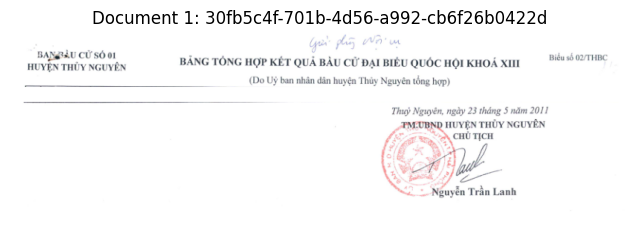

Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.


❓ Question: <image>
Trích xuất các thông tin sau trong văn bản: loại văn bản, số và ký hiệu văn bản, số viết tay ở góc trên bên phải, ngày ban hành, cơ quan chủ quản, cơ quan ban hành, người ký, trích yếu.
🎯 Expected: Loại văn bản: Bảng tổng hợp
Số và ký hiệu văn bản: 
Số viết tay ở góc trên bên phải: 
Ngày ban hành: 23/05/2011
Cơ quan chủ quản: BAN BẦU CỬ SỐ 01
Cơ quan ban hành: HUYỆN THỦY NGUYÊN
Người ký: Nguyễn Trần Lanh
Trích yếu: BẢNG TỔNG HỢP KẾT QUẢ BẦU CỬ ĐẠI BIỂU QUỐC HỘI KHOÁ XIII (Do Ủy ban nhân dân hu...
🤖 Model Response: **Loại văn bản:** Bảng tổng hợp kết quả bầu cử đại biểu Quốc hội khóa XIII

**Số và ký hiệu văn bản:** Biểu số 02/THBC

**Số viết tay ở góc trên bên phải:** (Không rõ)

**Ngày ban hành:** 23 tháng 5 năm 2011

**Cơ quan chủ quản:** Ủy ban nhân dân huyện Thủy Nguyên

**Cơ quan ban hành:** TM. UBND Huyện Thủy Nguyên

**Người ký:** Nguyễn Trần Lanh (Chủ tịch)


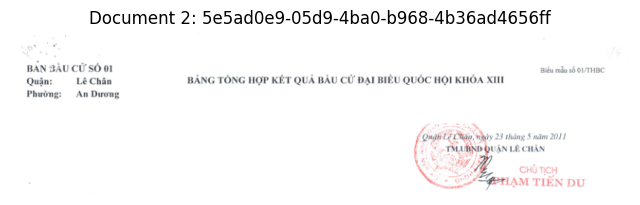

Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.


❓ Question: <image>
Trích xuất các thông tin sau trong văn bản: loại văn bản, số và ký hiệu văn bản, số viết tay ở góc trên bên phải, ngày ban hành, cơ quan chủ quản, cơ quan ban hành, người ký, trích yếu.
🎯 Expected: Loại văn bản: Bảng tổng hợp
Số và ký hiệu văn bản: 
Số viết tay ở góc trên bên phải: 14
Ngày ban hành: 23/05/2011
Cơ quan chủ quản: BAN BẦU CỬ SỐ 01
Cơ quan ban hành: Quận: LÊ CHÂN Phường: An Dương
Người ký: PHẠM TIẾN DU
Trích yếu: BẢNG TỔNG HỢP KẾT QUẢ BẦU CỬ ĐẠI BIỂU QUỐC HỘI KHÓA XIII
🤖 Model Response: Văn bản là Bản Bầu Cử số 01, Biểu mẫu số 01/THBC. Số viết tay ở góc trên bên phải không rõ ràng. Ngày ban hành là 23 tháng 5 năm 2011. Cơ quan chủ quản là Quận Lê Chân. Cơ quan ban hành là TM. UBND Quận Lê Chân. Người ký là Chủ tịch Phạm Tiến Du.


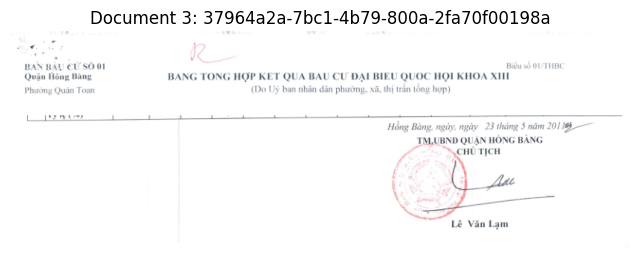

Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.


❓ Question: <image>
Trích xuất các thông tin sau trong văn bản: loại văn bản, số và ký hiệu văn bản, số viết tay ở góc trên bên phải, ngày ban hành, cơ quan chủ quản, cơ quan ban hành, người ký, trích yếu.
🎯 Expected: Loại văn bản: Bảng tổng hợp
Số và ký hiệu văn bản: 
Số viết tay ở góc trên bên phải: 
Ngày ban hành: 23/05/2011
Cơ quan chủ quản: BAN BẦU CỬ SỐ 01
Cơ quan ban hành: QUẬN HỒNG BÀNG
Người ký: Lê Văn Lạm
Trích yếu: BẢNG TỔNG HỢP KẾT QUẢ BẦU CỬ ĐẠI BIỂU QUỐC HỘI KHOÁ XIII (Do Uỷ ban nhân dân phường, xã,...
🤖 Model Response: **Loại văn bản:** Bản bầu cử số 01

**Số và ký hiệu văn bản:** Biểu số 01/THBC

**Số viết tay ở góc trên bên phải:** (Không rõ)

**Ngày ban hành:** 23 tháng 5 năm 2018

**Cơ quan chủ quản:** Ủy ban nhân dân phường, xã, thị trấn Hồng Bàng

**Cơ quan ban hành:** TM.UBND Quận Hồng Bàng

**Người ký:** Lê Văn Lạm


In [ ]:
### Test samples from our KIE dataset
print("🧪 Testing pre-trained model on KIE data:")
for i in range(min(3, len(train_data))):
    sample = train_data[i]
    image_path = os.path.join(EXTRACT_DIR, sample['image'])

    if os.path.exists(image_path):
        image = Image.open(image_path)

        plt.figure(figsize=(8,6))
        plt.imshow(image)
        plt.title(f"Document {i+1}: {sample['id']}")
        plt.axis('off')
        plt.show()

        pixel_values = load_image(image_path, max_num=12).to(torch.bfloat16).cuda()
        generation_config = dict(max_new_tokens=1024, do_sample=False, num_beams=3, repetition_penalty=2.0)

        # ✅ SỬ DỤNG PROMPT TỪ DỮ LIỆU TRAINING
        question = sample['conversations'][0]['value']
        expected_answer = sample['conversations'][1]['value']

        response = model.chat(tokenizer, pixel_values, question, generation_config)

        print(f'❓ Question: {question}')
        print(f'🎯 Expected: {expected_answer[:300]}...' if len(expected_answer) > 300 else f'🎯 Expected: {expected_answer}')
        print(f'🤖 Model Response: {response}')
        print("="*50)
    else:
        print(f"⚠️ Image not found: {image_path}")

In [ ]:
torch.cuda.empty_cache()

# **Prepare Your Customized Training Data**

In [ ]:
%cd /content/Vintern

/content/Vintern


## Convert exported data to Vintern format

Our exported data is already in the correct JSONL format for Vintern training, so we just need to copy it to the appropriate location and create the metadata file.

In [ ]:
import shutil

# Copy JSONL files to Vintern data directory
vintern_data_dir = "/content/Vintern/internvl_chat/shell/data"
os.makedirs(vintern_data_dir, exist_ok=True)

# Copy training data
train_jsonl_dest = os.path.join(vintern_data_dir, "vietnamese_kie_train.jsonl")
shutil.copy2(train_jsonl_path, train_jsonl_dest)

# Copy validation data if exists
val_jsonl_dest = None
if os.path.exists(val_jsonl_path):
    val_jsonl_dest = os.path.join(vintern_data_dir, "vietnamese_kie_val.jsonl")
    shutil.copy2(val_jsonl_path, val_jsonl_dest)

print(f"✅ Copied training data to: {train_jsonl_dest}")
if val_jsonl_dest:
    print(f"✅ Copied validation data to: {val_jsonl_dest}")

print(f"📁 Images will be loaded from: {images_dir}")

✅ Copied training data to: /content/Vintern/internvl_chat/shell/data/vietnamese_kie_train.jsonl
✅ Copied validation data to: /content/Vintern/internvl_chat/shell/data/vietnamese_kie_val.jsonl
📁 Images will be loaded from: /content/pla_kie/images


## Create meta file to manage the meta information of all datasets

In [ ]:
# Create metadata for our Vietnamese KIE dataset
metadata_datasets = {
    "vietnamese-kie-train": {
        "root": images_dir,  # Path to images directory from export
        "annotation": train_jsonl_dest,
        "data_augment": False,
        "repeat_time": 1,
        "length": len(train_data)
    }
}

# Add validation data if exists
if val_jsonl_dest and len(val_data) > 0:
    metadata_datasets["vietnamese-kie-val"] = {
        "root": images_dir,
        "annotation": val_jsonl_dest,
        "data_augment": False,
        "repeat_time": 1,
        "length": len(val_data)
    }

# Save metadata file
metadata_path = '/content/Vintern/internvl_chat/shell/data/vietnamese_kie_datasets.json'
with open(metadata_path, 'w', encoding='utf-8') as f:
    json.dump(metadata_datasets, f, ensure_ascii=False, indent=4)

print(f"✅ Created metadata file: {metadata_path}")
print(f"📊 Training samples: {len(train_data)}")
print(f"📊 Validation samples: {len(val_data)}")

# Display metadata
print("\n📋 Metadata structure:")
print(json.dumps(metadata_datasets, ensure_ascii=False, indent=2))

✅ Created metadata file: /content/Vintern/internvl_chat/shell/data/vietnamese_kie_datasets.json
📊 Training samples: 368
📊 Validation samples: 0

📋 Metadata structure:
{
  "vietnamese-kie-train": {
    "root": "/content/pla_kie/images",
    "annotation": "/content/Vintern/internvl_chat/shell/data/vietnamese_kie_train.jsonl",
    "data_augment": false,
    "repeat_time": 1,
    "length": 368
  }
}


# Training

## LoRA fine-tuning for Vietnamese KIE

In [ ]:
# Create training script optimized for Vietnamese KIE task
train_bash_content = '''set -x

GPUS=${GPUS:-1}
BATCH_SIZE=${BATCH_SIZE:-2}
PER_DEVICE_BATCH_SIZE=${PER_DEVICE_BATCH_SIZE:-2}
GRADIENT_ACC=$((BATCH_SIZE / PER_DEVICE_BATCH_SIZE / GPUS))

export PYTHONPATH="${PYTHONPATH}:$(pwd)"
export MASTER_PORT=34229
export TF_CPP_MIN_LOG_LEVEL=3
export LAUNCHER=pytorch

OUTPUT_DIR='/content/work_dirs/internvl_chat_v2_0/Vintern_1B_v3_5_vietnamese_kie_lora'

if [ ! -d "$OUTPUT_DIR" ]; then
  mkdir -p "$OUTPUT_DIR"
fi

# Fine-tuning for Vietnamese document KIE task
# Optimized for header information extraction
torchrun \
  --nnodes=1 \
  --node_rank=0 \
  --master_addr=127.0.0.1 \
  --nproc_per_node=${GPUS} \
  --master_port=${MASTER_PORT} \
  internvl/train/internvl_chat_finetune.py \
  --model_name_or_path "/content/Vintern/pretrained/Vintern-1B-v3_5" \
  --conv_style "Hermes-2" \
  --output_dir ${OUTPUT_DIR} \
  --meta_path "/content/Vintern/internvl_chat/shell/data/vietnamese_kie_datasets.json" \
  --overwrite_output_dir True \
  --force_image_size 448 \
  --max_dynamic_patch 6 \
  --down_sample_ratio 0.5 \
  --drop_path_rate 0.0 \
  --freeze_llm True \
  --freeze_mlp True \
  --freeze_backbone True \
  --use_llm_lora 16 \
  --vision_select_layer -1 \
  --dataloader_num_workers 4 \
  --bf16 True \
  --num_train_epochs 3 \
  --per_device_train_batch_size ${PER_DEVICE_BATCH_SIZE} \
  --gradient_accumulation_steps ${GRADIENT_ACC} \
  --evaluation_strategy "no" \
  --save_strategy "steps" \
  --save_steps 100 \
  --save_total_limit 3 \
  --learning_rate 2e-4 \
  --weight_decay 0.01 \
  --warmup_ratio 0.05 \
  --lr_scheduler_type "cosine" \
  --logging_steps 10 \
  --max_seq_length 2048 \
  --do_train True \
  --grad_checkpoint True \
  --group_by_length True \
  --dynamic_image_size True \
  --use_thumbnail True \
  --ps_version 'v2' \
  --deepspeed "zero_stage1_config.json" \
  --report_to "tensorboard" \
  2>&1 | tee -a "${OUTPUT_DIR}/training_log.txt"
'''

In [ ]:
# Save training script
script_path = "/content/Vintern/internvl_chat/shell/internvl2.0/2nd_finetune/vietnamese_kie_lora_finetune.sh"
with open(script_path, "w") as text_file:
    text_file.write(train_bash_content)

print(f"✅ Created training script: {script_path}")
print("🚀 Ready to start training...")

✅ Created training script: /content/Vintern/internvl_chat/shell/internvl2.0/2nd_finetune/vietnamese_kie_lora_finetune.sh
🚀 Ready to start training...


Let's start training. This will take approximately 30-60 minutes depending on your dataset size and GPU.

In [ ]:
%cd /content/Vintern/internvl_chat
!sh shell/internvl2.0/2nd_finetune/vietnamese_kie_lora_finetune.sh

/content/Vintern/internvl_chat
+ GPUS=1
+ BATCH_SIZE=2
+ PER_DEVICE_BATCH_SIZE=2
+ GRADIENT_ACC=1
+ pwd
+ export PYTHONPATH=/env/python:/content/Vintern/internvl_chat
+ export MASTER_PORT=34229
+ export TF_CPP_MIN_LOG_LEVEL=3
+ export LAUNCHER=pytorch
+ OUTPUT_DIR=/content/work_dirs/internvl_chat_v2_0/Vintern_1B_v3_5_vietnamese_kie_lora
+ [ ! -d /content/work_dirs/internvl_chat_v2_0/Vintern_1B_v3_5_vietnamese_kie_lora ]
+ mkdir -p /content/work_dirs/internvl_chat_v2_0/Vintern_1B_v3_5_vietnamese_kie_lora
+ torchrun --nnodes=1 --node_rank=0 --master_addr=127.0.0.1 --nproc_per_node=1 --master_port=34229 internvl/train/internvl_chat_finetune.py --model_name_or_path /content/Vintern/pretrained/Vintern-1B-v3_5 --conv_style Hermes-2 --output_dir /content/work_dirs/internvl_chat_v2_0/Vintern_1B_v3_5_vietnamese_kie_lora --meta_path /content/Vintern/internvl_chat/shell/data/vietnamese_kie_datasets.json --overwrite_output_dir True --force_image_size 448 --max_dynamic_patch 6 --down_sample_ratio 0

In [ ]:
import torch
torch.cuda.empty_cache()

## Merging LoRA Weights

In [ ]:
# LoRA merge script for Vietnamese KIE model
merge_lora_content = '''import torch
import sys
sys.path.append("/content/Vintern/internvl_chat")
from internvl.model.internvl_chat import InternVLChatModel
from transformers import AutoTokenizer
import argparse

argparse = argparse.ArgumentParser()
argparse.add_argument("input_path", type=str, help="Path to the input model")
argparse.add_argument("output_path", type=str, help="Path to the output model")
args = argparse.parse_args()

print("Loading Vietnamese KIE fine-tuned model...")
model = InternVLChatModel.from_pretrained(
    args.input_path, low_cpu_mem_usage=True, torch_dtype=torch.bfloat16).eval()
print("Loading tokenizer...")
tokenizer = AutoTokenizer.from_pretrained(args.input_path, trust_remote_code=True)

if model.config.use_backbone_lora:
    model.vision_model.merge_and_unload()
    model.vision_model = model.vision_model.model
    model.config.use_backbone_lora = 0
if model.config.use_llm_lora:
    model.language_model.merge_and_unload()
    model.language_model = model.language_model.model
    model.config.use_llm_lora = 0

print("Saving merged model...")
model.save_pretrained(args.output_path)
print("Saving tokenizer...")
tokenizer.save_pretrained(args.output_path)
print("✅ Vietnamese KIE model merge completed!")
'''

with open("/content/Vintern/internvl_chat/tools/merge_lora.py", "w") as text_file:
    text_file.write(merge_lora_content)

In [ ]:
# Merge LoRA weights
%cd /content/Vintern/internvl_chat
!python tools/merge_lora.py /content/work_dirs/internvl_chat_v2_0/Vintern_1B_v3_5_vietnamese_kie_lora \
                            /content/plakie

/content/Vintern/internvl_chat
/usr/local/lib/python3.12/dist-packages/timm/models/layers/__init__.py:48: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
2025-11-05 07:02:39.260691: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1762326159.281935    7813 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1762326159.288456    7813 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1762326159.304771    7813 computation_placer.cc:177] computation placer already registered. Please check linkage and av

## Wrapping into AutoModel

In [ ]:
# Check merged model directory
!ls /content/work_dirs/internvl_chat_v2_0/vnkie

ls: cannot access '/content/work_dirs/internvl_chat_v2_0/vnkie': No such file or directory


In [ ]:
# Copy necessary files for AutoModel compatibility
!cp /content/Vintern/pretrained/Vintern-1B-v3_5/*.py \
    /content/plakie

In [ ]:
# Copy config file
!cp /content/Vintern/pretrained/Vintern-1B-v3_5/config.json \
    /content/plakie

# Inference with fine-tuned Vietnamese KIE model

In [ ]:
# Load the fine-tuned model for Vietnamese KIE
model_name = "/content/plakie"

model = AutoModel.from_pretrained(model_name,
                                  torch_dtype=torch.bfloat16,
                                  use_flash_attn=False,
                                  low_cpu_mem_usage=True,
                                  trust_remote_code=True).eval().cuda()
tokenizer = AutoTokenizer.from_pretrained(model_name, trust_remote_code=True, use_fast=False)

print("✅ Fine-tuned Vietnamese KIE model loaded successfully!")

✅ Fine-tuned Vietnamese KIE model loaded successfully!


🧪 Testing fine-tuned model on Vietnamese KIE data:
🎯 Expected improvements in Vietnamese document understanding and KIE accuracy


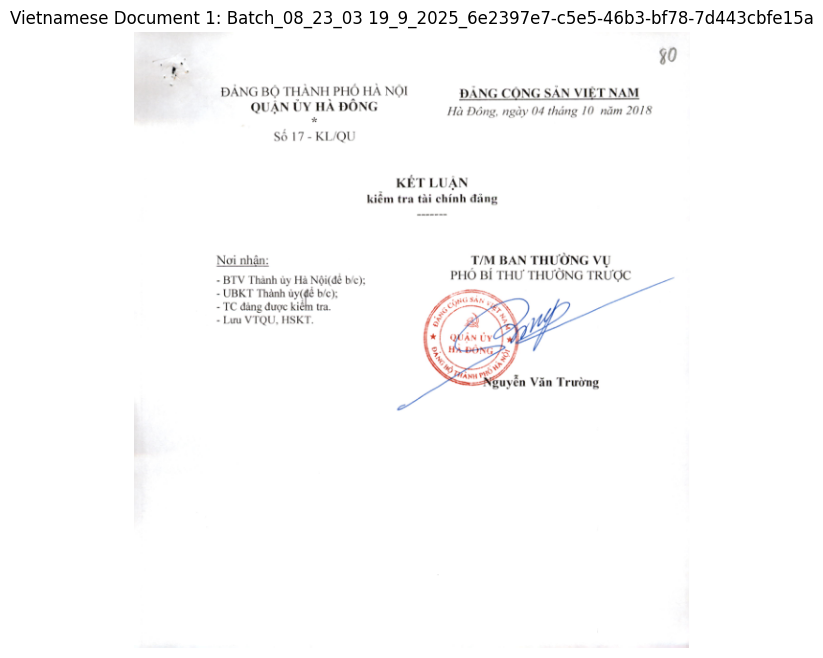

Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.


📋 Document ID: Batch_08_23_03 19_9_2025_6e2397e7-c5e5-46b3-bf78-7d443cbfe15a
❓ Question: <image>
Bạn là chuyên gia trích xuất thông tin từ tài liệu hành chính Việt Nam. Hãy trích xuất các thông tin sau: Loại văn bản, Số và ký hiệu văn bản, Số viết tay ở góc trên bên phải, Cơ quan chủ quản, Cơ quan ban hành, Ngày tháng năm ban hành, Trích yếu, Người ký.

Trả về JSON theo cấu trúc sau:
{
  "document_type": "",
  "document_number_and_symbol": "",
  "handwritten_number": "",
  "issue_date": "",
  "supervising_authority": "",
  "issuing_authority": "",
  "signer_name": "",
  "summary": ""
}

🎯 Expected KIE Output:
{
  "document_type": "Kết luận",
  "document_number_and_symbol": "17 - KL/QU",
  "handwritten_number": "80",
  "issue_date": "04/10/2018",
  "supervising_authority": "ĐẢNG BỘ THÀNH PHỐ HÀ NỘI",
  "issuing_authority": "QUẬN ỦY HÀ ĐÔNG",
  "signer_name": "Nguyễn Văn Trường",
  "summary": "KẾT LUẬN kiểm tra tài chính đảng"
}

🤖 Fine-tuned Model Output:
{
  "document_type": "Kết luận"

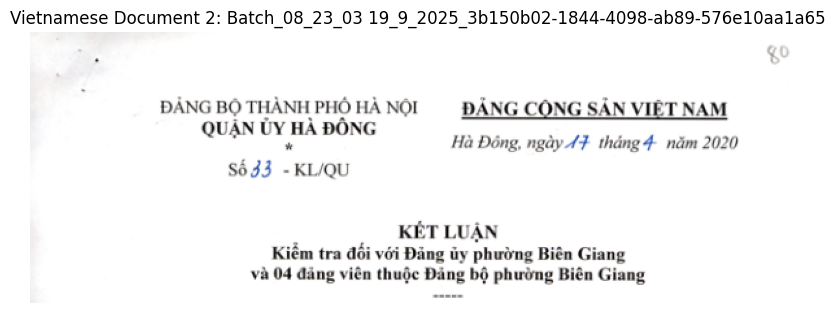

Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.


📋 Document ID: Batch_08_23_03 19_9_2025_3b150b02-1844-4098-ab89-576e10aa1a65
❓ Question: <image>
Bạn là chuyên gia trích xuất thông tin từ tài liệu hành chính Việt Nam. Hãy trích xuất các thông tin sau: Loại văn bản, Số và ký hiệu văn bản, Số viết tay ở góc trên bên phải, Cơ quan chủ quản, Cơ quan ban hành, Ngày tháng năm ban hành, Trích yếu, Người ký.

Trả về JSON theo cấu trúc sau:
{
  "document_type": "",
  "document_number_and_symbol": "",
  "handwritten_number": "",
  "issue_date": "",
  "supervising_authority": "",
  "issuing_authority": "",
  "signer_name": "",
  "summary": ""
}

🎯 Expected KIE Output:
{
  "document_type": "Kết luận",
  "document_number_and_symbol": "33 - KL/QU",
  "handwritten_number": "80",
  "issue_date": "17/04/2020",
  "supervising_authority": "ĐẢNG BỘ THÀNH PHỐ HÀ NỘI",
  "issuing_authority": "QUẬN ỦY HÀ ĐÔNG",
  "signer_name": "",
  "summary": "KẾT LUẬN Kiểm tra đối với Đảng ủy phường Biên Giang và 04 đảng viên thuộc Đảng bộ phường Biên Giang"
}

🤖 Fine-t

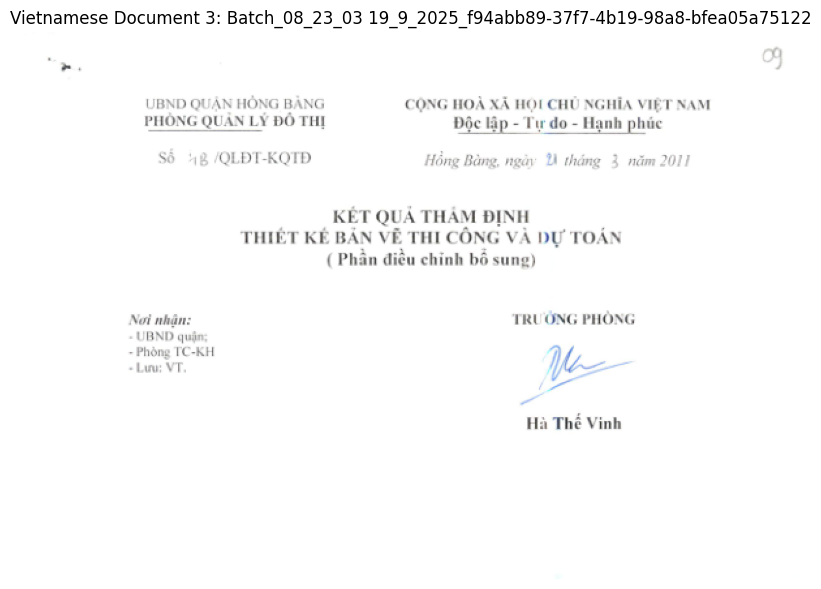

Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.


📋 Document ID: Batch_08_23_03 19_9_2025_f94abb89-37f7-4b19-98a8-bfea05a75122
❓ Question: <image>
Bạn là chuyên gia trích xuất thông tin từ tài liệu hành chính Việt Nam. Hãy trích xuất các thông tin sau: Loại văn bản, Số và ký hiệu văn bản, Số viết tay ở góc trên bên phải, Cơ quan chủ quản, Cơ quan ban hành, Ngày tháng năm ban hành, Trích yếu, Người ký.

Trả về JSON theo cấu trúc sau:
{
  "document_type": "",
  "document_number_and_symbol": "",
  "handwritten_number": "",
  "issue_date": "",
  "supervising_authority": "",
  "issuing_authority": "",
  "signer_name": "",
  "summary": ""
}

🎯 Expected KIE Output:
{
  "document_type": "Khác",
  "document_number_and_symbol": "18 /QLĐT-KQTĐ",
  "handwritten_number": "09",
  "issue_date": "21/03/2011",
  "supervising_authority": "UBND QUẬN HỒNG BÀNG",
  "issuing_authority": "PHÒNG QUẢN LÝ ĐÔ THỊ",
  "signer_name": "Hà Thế Vinh",
  "summary": "KẾT QUẢ THẨM ĐỊNH THIẾT KẾ BẢN VẼ THI CÔNG VÀ DỰ TOÁN (Phần điều chỉnh bổ sung)"
}

🤖 Fine-tuned Model

In [ ]:
### Test fine-tuned model on Vietnamese KIE task
print("🧪 Testing fine-tuned model on Vietnamese KIE data:")
print("🎯 Expected improvements in Vietnamese document understanding and KIE accuracy")
print("="*70)

# Test on validation data if available, otherwise use training data
test_data = train_data if len(train_data) > 0 else train_data[-3:]  # Use last 3 from training if no val

for i, sample in enumerate(train_data[100:103]):
    image_path = os.path.join(EXTRACT_DIR,"images", sample['image'])

    if os.path.exists(image_path):
        image = Image.open(image_path)

        plt.figure(figsize=(10, 8))
        plt.imshow(image)
        plt.title(f"Vietnamese Document {i+1}: {sample['id']}")
        plt.axis('off')
        plt.show()

        pixel_values = load_image(image_path, max_num=12).to(torch.bfloat16).cuda()
        generation_config = dict(max_new_tokens=2048, do_sample=False, num_beams=3, repetition_penalty=1.2)

        # Use the exact prompt from training data
        question = sample['conversations'][0]['value']
        expected_answer = sample['conversations'][1]['value']

        response = model.chat(tokenizer, pixel_values, question, generation_config)

        print(f'📋 Document ID: {sample["id"]}')
        print(f'❓ Question: {question}')
        print(f'\n🎯 Expected KIE Output:')
        print(expected_answer)
        print(f'\n🤖 Fine-tuned Model Output:')
        print(response)
        print("\n" + "="*70)
    else:
        print(f"⚠️ Image not found: {image_path}")

In [ ]:
### Test with a new document (if you have test images)
print("🆕 Test with new Vietnamese documents:")
print("Upload your Vietnamese administrative documents to test the fine-tuned model")

# You can upload test images and use this code:
test_image_path = "/content/tu_kie/images/0c116569-fdd1-496c-8f7f-2a9dd0ec449a_header.png"
if os.path.exists(test_image_path):
    image = Image.open(test_image_path)
    plt.figure(figsize=(10, 8))
    plt.imshow(image)
    plt.title("Test Vietnamese Document")
    plt.axis('off')
    plt.show()

    pixel_values = load_image(test_image_path, max_num=12).to(torch.bfloat16).cuda()
    generation_config = dict(max_new_tokens=2048, do_sample=False, num_beams=3, repetition_penalty=1.2)

    question = '<image>\nBạn là chuyên gia trích xuất thông tin từ tài liệu hành chính Việt Nam. Hãy trích xuất các thông tin sau: Loại văn bản, Số và ký hiệu văn bản, Số viết tay ở góc trên bên phải, Cơ quan chủ quản, Cơ quan ban hành, Ngày tháng năm ban hành, Trích yếu, Người ký.\n\nTrả về JSON theo cấu trúc sau:\n{\n  \"document_type\": \"\",\n  \"document_number_and_symbol\": \"\",\n  \"handwritten_number\": \"\",\n  \"issue_date\": \"\",\n  \"supervising_authority\": \"\",\n  \"issuing_authority\": \"\",\n  \"signer_name\": \"\",\n  \"summary\": \"\"\n}'

    response = model.chat(tokenizer, pixel_values, question, generation_config)
    print(f'🤖 KIE Extraction Result:\n{response}')

🆕 Test with new Vietnamese documents:
Upload your Vietnamese administrative documents to test the fine-tuned model


## Save and Upload Fine-tuned Model (Optional)

In [ ]:
# Optional: Upload to Hugging Face Hub
# First login to HF: !huggingface-cli login

# model_repo_name = "your-username/vintern-1b-vietnamese-kie"
# model.push_to_hub(model_repo_name, private=True)
# tokenizer.push_to_hub(model_repo_name, private=True)

print("✅ Fine-tuning completed successfully!")
print("🎯 Your Vietnamese KIE model is ready for production use")
print("📊 Model specialized for Vietnamese administrative document information extraction")
print("🔧 Optimized for: loại văn bản, số ký hiệu, ngày ban hành, cơ quan ban hành, người ký, trích yếu")

# Summary

This notebook demonstrated how to fine-tune Vintern-1B-v3_5 on your exported Vietnamese KIE dataset. The key achievements:

✅ **Successfully loaded exported KIE data** from your document processing system

✅ **Fine-tuned Vintern model** specifically for Vietnamese administrative documents

✅ **Optimized for 8 key fields**: loại văn bản, số và ký hiệu văn bản, số viết tay, ngày ban hành, cơ quan chủ quản, cơ quan ban hành, người ký, trích yếu

✅ **Ready for production deployment** in your KIE system

The fine-tuned model should now perform significantly better on Vietnamese document KIE tasks compared to the base model, especially for the specific document types and fields in your training data.

**Next Steps:**
1. Integrate the fine-tuned model back into your KIE system
2. Compare performance with your current Google AI model
3. Collect more training data and iterate on the fine-tuning process
4. Consider fine-tuning with larger datasets for even better performance

Check out more about us: [Fifth Civil Defender - 5CD - AI](https://huggingface.co/5CD-AI)

In [ ]:
import shutil
import os

if os.path.exists("/content/kie_dataset"):
    shutil.rmtree("/content/kie_dataset")
    print("✅ Thư mục '/content/kie_dataset' đã được xóa thành công.")
else:
    print("ℹ️ Thư mục '/content/kie_dataset' không tồn tại.")

✅ Thư mục '/content/kie_dataset' đã được xóa thành công.


In [ ]:
import shutil
import os

if os.path.exists("/content/tu"):
    shutil.rmtree("/content/tu")
    print("✅ Thư mục '/content/tu' đã được xóa thành công.")
else:
    print("ℹ️ Thư mục '/content/tu' không tồn tại.")

✅ Thư mục '/content/tu' đã được xóa thành công.


In [ ]:
# Thay đổi 'ten_file_zip.zip' thành tên file zip bạn muốn tạo
# Thay đổi 'duong_dan_thu_muc' thành đường dẫn đến thư mục bạn muốn nén
!zip -r /content/plakie_model.zip /content/plakie

  adding: content/plakie/ (stored 0%)
  adding: content/plakie/vocab.json (deflated 61%)
  adding: content/plakie/tokenizer.json (deflated 81%)
  adding: content/plakie/merges.txt (deflated 57%)
  adding: content/plakie/configuration_intern_vit.py (deflated 70%)
  adding: content/plakie/special_tokens_map.json (deflated 68%)
  adding: content/plakie/model.safetensors (deflated 21%)
  adding: content/plakie/modeling_intern_vit.py (deflated 75%)
  adding: content/plakie/configuration_internvl_chat.py (deflated 71%)
  adding: content/plakie/tokenizer_config.json (deflated 85%)
  adding: content/plakie/config.json (deflated 76%)
  adding: content/plakie/added_tokens.json (deflated 66%)
  adding: content/plakie/conversation.py (deflated 79%)
  adding: content/plakie/generation_config.json (deflated 21%)
  adding: content/plakie/modeling_internvl_chat.py (deflated 77%)


In [ ]:
# Thay đổi 'ten_file_zip.zip' thành tên file zip bạn muốn tạo
# Thay đổi 'duong_dan_thu_muc' thành đường dẫn đến thư mục bạn muốn nén
!zip -r vnkie_model.zip /content/work_dirs/internvl_chat_v2_0/Vintern_1B_v3_5_vietnamese_kie_merged

  adding: content/work_dirs/internvl_chat_v2_0/Vintern_1B_v3_5_vietnamese_kie_merged/ (stored 0%)
  adding: content/work_dirs/internvl_chat_v2_0/Vintern_1B_v3_5_vietnamese_kie_merged/conversation.py (deflated 79%)
  adding: content/work_dirs/internvl_chat_v2_0/Vintern_1B_v3_5_vietnamese_kie_merged/modeling_intern_vit.py (deflated 75%)
  adding: content/work_dirs/internvl_chat_v2_0/Vintern_1B_v3_5_vietnamese_kie_merged/model.safetensors (deflated 21%)
  adding: content/work_dirs/internvl_chat_v2_0/Vintern_1B_v3_5_vietnamese_kie_merged/added_tokens.json (deflated 66%)
  adding: content/work_dirs/internvl_chat_v2_0/Vintern_1B_v3_5_vietnamese_kie_merged/config.json (deflated 76%)
  adding: content/work_dirs/internvl_chat_v2_0/Vintern_1B_v3_5_vietnamese_kie_merged/configuration_internvl_chat.py (deflated 71%)
  adding: content/work_dirs/internvl_chat_v2_0/Vintern_1B_v3_5_vietnamese_kie_merged/merges.txt (deflated 57%)
  adding: content/work_dirs/internvl_chat_v2_0/Vintern_1B_v3_5_vietnamese

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!cp /content/vnkie_model.zip /content/drive/MyDrive/